Adapted from the book “Hands-On Machine Learning with Scikit-Learn and
TensorFlow” by Aurélien Géron

Adapted from original
[notebook](https://github.com/ageron/handson-ml3/blob/main/02_end_to_end_machine_learning_project.ipynb)
by Aurélien Géron This notebook requires Python 3.7 or later and
scikit-learn 1.0.1 or later.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.impute import KNNImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, PolynomialFeatures
from sklearn.feature_selection import SelectFromModel
from pandas.plotting import scatter_matrix

In [23]:
housing = pd.read_csv("housing.csv")

In [24]:
# look at the first few rows of the housing dataframe
housing.head()

In [25]:
# summarize the data
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

In [26]:
housing.describe()

In [27]:
# just one categorical feature
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [28]:
# Before doing much more, split!
train, test = train_test_split(housing, test_size=0.2, random_state=42)

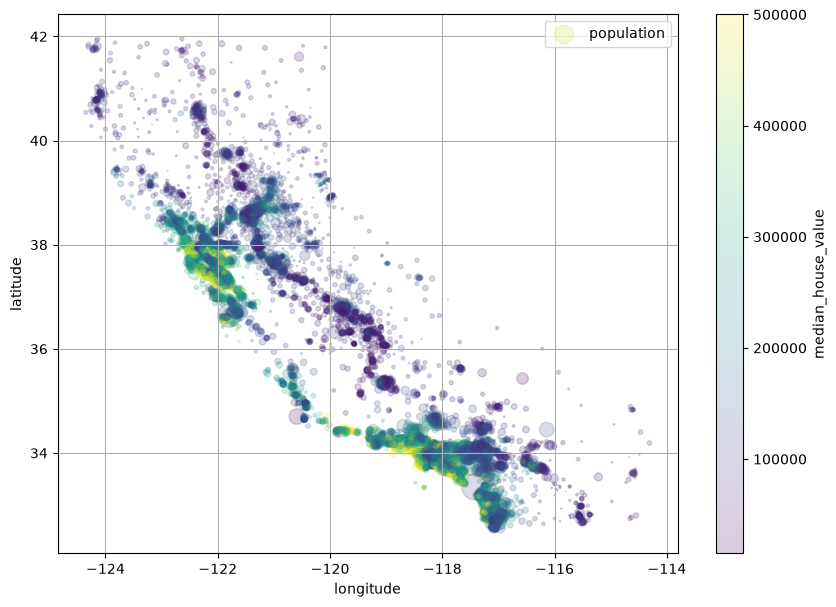

In [29]:
# how about a heat map?
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    grid=True,
    s=housing["population"] / 100,
    label="population",
    c="median_house_value",
    cmap="viridis",
    colorbar=True,
    legend=True,
    figsize=(10, 7),
    alpha=0.2,
)
plt.show()

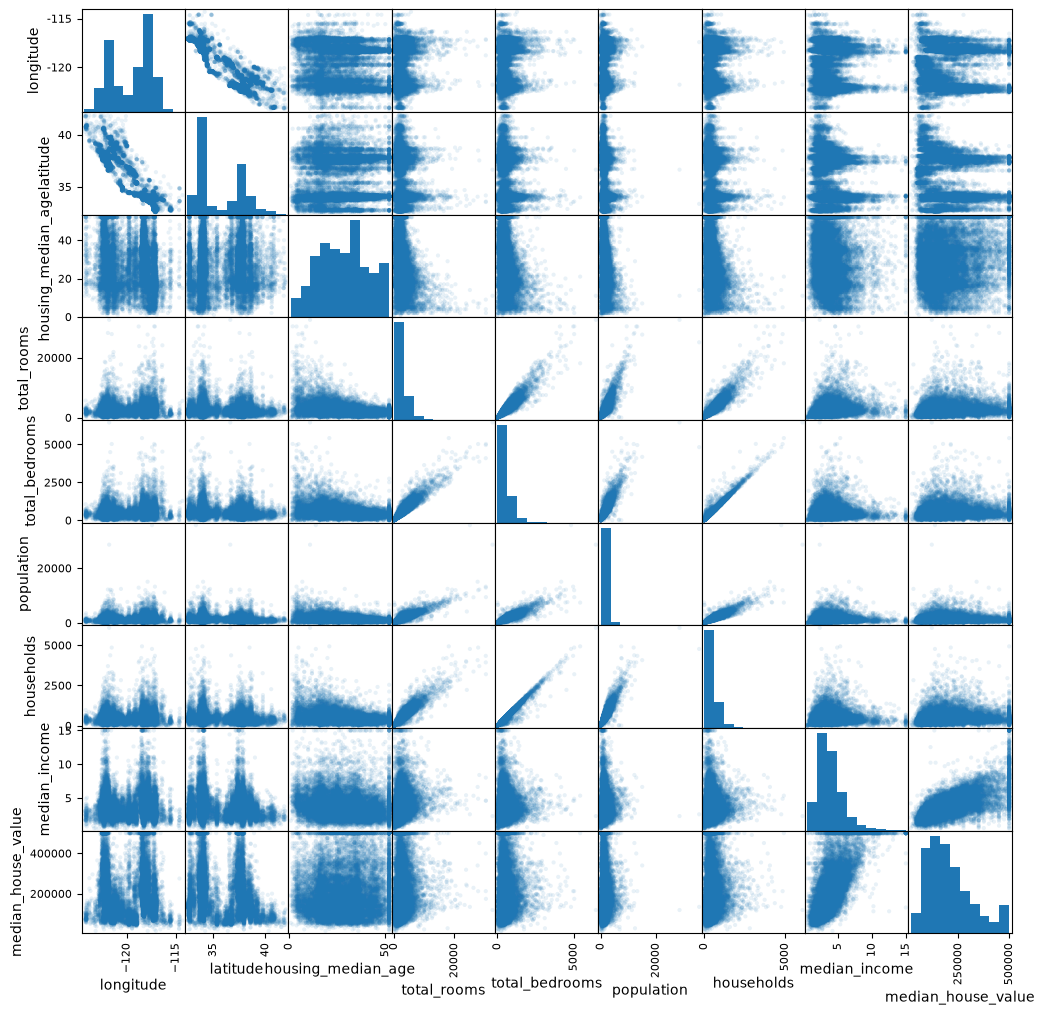

In [30]:
# What kinds of scales are we looking at?
scatter_matrix(train, figsize=(12, 12), alpha=0.1)
plt.show()

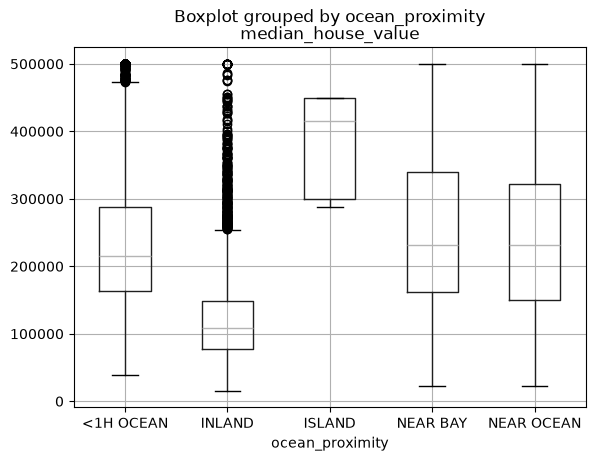

In [31]:
train.boxplot(column="median_house_value", by="ocean_proximity")

## Missing features

In [32]:
# First, let's look at the missing values in the total_bedrooms column
null_rows_idx = train.isnull().any(axis=1)
print(f"Missing {len(train[null_rows_idx])} of {len(train)} rows")
train.loc[null_rows_idx].head()

Missing 163 of 16512 rows

## Categorical Encoding

In [33]:
# Option 1: Ordinal encoding
# naive implementation
# If ordinal, needs to make sense - default values are alphabetical
ordinal_encoder = OrdinalEncoder(
    categories=[["ISLAND", "NEAR BAY", "NEAR OCEAN", "<1H OCEAN", "INLAND"]]
)

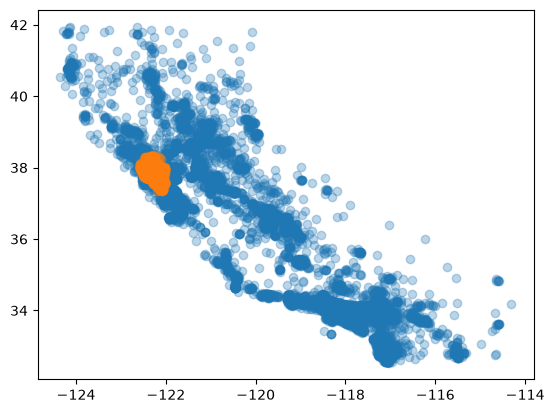

In [34]:
# Let's confirm what "near bay" means - San Francisco Bay area?
near_bay = train["ocean_proximity"] == "NEAR BAY"
plt.scatter(train["longitude"], train["latitude"], alpha=0.3)
plt.scatter(train["longitude"][near_bay], train["latitude"][near_bay], alpha=0.3)

## Transformation Pipelines

In [35]:
num_attribs = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
]

# The numeric features get the usual treatment
num_pipeline = make_pipeline(
    KNNImputer(),
    # TODO: Add interaction effects
    StandardScaler(),
)

# altogether now
preprocessing = make_column_transformer(
    (num_pipeline, num_attribs),
    (ordinal_encoder, ["ocean_proximity"]),
)

preprocessing

In [36]:
# Finally we can train some kind of model
pipeline = make_pipeline(
    preprocessing,
    LinearRegression(),
)
# cross-validate
cv = cross_val_score(pipeline, train, train["median_house_value"])
print(cv.mean(), cv)

0.6367206726570345 [0.63242941 0.66037511 0.62929331 0.63727367 0.62423187]

In [37]:
# Convenient function to evaluate performance
def plot_predictions(actual, pred):
    plt.scatter(actual, pred, alpha=0.1)
    plt.plot([0, 500000], [0, 500000], color="red")
    plt.xlabel("Actual Median House Value ($)")
    plt.ylabel("Predicted Median House Value ($)")
    mae = mean_absolute_error(actual, pred)
    plt.text(300000, 10000, f"MAE = ${mae:.2f}")

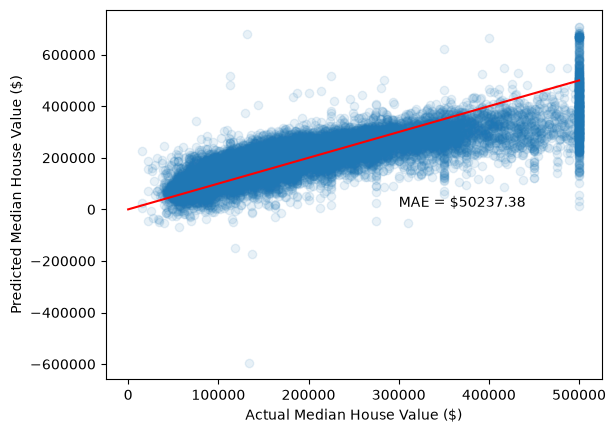

In [38]:
pipeline.fit(train, train["median_house_value"])
y_est = pipeline.predict(train)
plot_predictions(train["median_house_value"], y_est)